# What do non-SNP variants add? Significant blocks by class, GEA and per-garden GWAS

**Unit:** unmerged clq r²=0.9 tiling block, assigned identically for every class and both
scans. **Significant for a class:** the class's lead (min-p) record in the block clears that
class's own Bonferroni 0.05/n_records, in ≥1 climate axis (GEA: raw LFMM gen9, MAF>0.05,
bio1–19 + pc1–3) or ≥1 garden (GWAS: GEMMA per garden, 30 gardens, MAC≥5).
**non-SNP** = small indels + SVs tested as one pool (one Bonferroni); **SV** = SVs alone.
The GWAS has no separate small-indel scan.

**Status of a non-SNP / SV block** relative to SNPs:
- *shared with SNP* — the block is also SNP-significant (any axis/garden)
- *new, SNP near-miss* — not SNP-significant, but its best SNP lead is within 2 orders of
  magnitude of the SNP Bonferroni bar. Largely a threshold effect: the SV bar is ~2 orders
  easier than the SNP bar simply because there are ~70× fewer SVs.
- *new, SNP-blind* — the best SNP in the block is >2 orders below the SNP bar

Raw p, no inflation correction (project decision). Numbers from
`genes/convergence/class_signal_counts.py`.

In [1]:
import os, sys, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib_venn import venn2, venn3
def _tree_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    while d != os.path.dirname(d):
        if os.path.basename(d) == "grenenet_selection" and os.path.exists(os.path.join(d, "lib.py")):
            return d
        d = os.path.dirname(d)
    raise RuntimeError("no grenenet_selection root above " + os.getcwd())
GS = _tree_root()
sys.path.insert(0, f"{GS}/genes/convergence")
import plot_theme as TH
TH.apply()
RES = f"{GS}/genes/convergence/results"
PLOTS = f"{RES}/plots"; os.makedirs(PLOTS, exist_ok=True)

TAB = pd.read_csv(f"{RES}/class_signal_counts.csv")
CELLS = pd.read_csv(f"{RES}/class_signal_cells.csv", dtype={"unit": str})
BLK = pd.read_csv(f"{RES}/class_signal_blocks.csv")

AXES = [f"bio{i}" for i in range(1, 20)] + ["pc1", "pc2", "pc3"]
BIONAME = {"bio1": "annual mean temp", "bio2": "mean diurnal range", "bio3": "isothermality",
           "bio4": "temp seasonality", "bio5": "max temp warmest month",
           "bio6": "min temp coldest month", "bio7": "temp annual range",
           "bio8": "temp wettest quarter", "bio9": "temp driest quarter",
           "bio10": "temp warmest quarter", "bio11": "temp coldest quarter",
           "bio12": "annual precip", "bio13": "precip wettest month",
           "bio14": "precip driest month", "bio15": "precip seasonality",
           "bio16": "precip wettest quarter", "bio17": "precip driest quarter",
           "bio18": "precip warmest quarter", "bio19": "precip coldest quarter",
           "pc1": "climate PC1", "pc2": "climate PC2", "pc3": "climate PC3"}
_s = json.load(open(f"{GS}/r3_persite_gwas/results/gemma_gwas/persite_gwas_summary.json"))
GARDEN_BIO1 = {str(g): float(b) for g, b in zip(_s["gardens"], _s["bio1"])}
GARDENS = sorted(GARDEN_BIO1, key=GARDEN_BIO1.get)                # cold -> hot

COL = {"snp": "#A6A6A6", "nonsnp": TH.GREENS[1], "smallindel": TH.GREENS[0], "sv": TH.GREENS[2]}
LAB = {"snp": "SNP", "nonsnp": "non-SNP", "smallindel": "small indel", "sv": "SV"}
STATUS = ["shared_with_snp", "new_snp_near_miss", "new_snp_blind"]
SCOL = {"shared_with_snp": "#CFCFCF", "new_snp_near_miss": TH.GREENS[0],
        "new_snp_blind": TH.GREENS[2]}
SLAB = {"shared_with_snp": "shared with SNP", "new_snp_near_miss": "new · SNP near-miss",
        "new_snp_blind": "new · SNP-blind"}

def blocks(scan, cls):
    return set(BLK.loc[(BLK.scan == scan) & (BLK.variant_class == cls), "block"])

TESTED = TAB.set_index(["scan", "variant_class"]).tested_blocks.to_dict()

def tlab(name, scan, cls, n=None):
    # one denominator line: significant / tested blocks of that class and scan
    n = len(blocks(scan, cls)) if n is None else n
    t = TESTED[(scan, cls)]
    return f"{name}: {n:,} of {t:,} tested blocks ({100 * n / t:.1f}%)"

def under(ax, lines, y=-0.02):
    # denominators as an in-panel text block below the diagram (not in the circle labels,
    # which matplotlib_venn places next to the circles and which then collide)
    ax.annotate("\n".join(lines), (0.5, y), xycoords="axes fraction", ha="center", va="top",
                fontsize=8.5, color=TH.TICK, linespacing=1.5)

show = TAB.set_index(["scan", "variant_class"])[
    ["tested_blocks", "sig_blocks", "shared_with_snp_any_unit", "class_only_any_unit",
     "pct_class_only_any_unit", "class_only_snp_near_miss", "pct_gain_over_snp"]]
show.columns = ["tested", "significant", "shared w/ SNP", "new", "% new", "new: SNP near-miss",
                "% gain over SNP"]
show.fillna("").astype(str).replace(r"\.0$", "", regex=True)

tested significant shared w/ SNP  new % new  \
scan variant_class                                               
GEA  snp            58137        1431                            
     nonsnp         49592        1318           520  798  60.5   
     smallindel     49487        1297           514  783  60.4   
     sv              8954         279            97  182  65.2   
GWAS snp            58247          79                            
     nonsnp         51024          57            14   43  75.4   
     sv              7057          16             2   14  87.5   

                   new: SNP near-miss % gain over SNP  
scan variant_class                                     
GEA  snp                                               
     nonsnp                       418            55.8  
     smallindel                   416            54.7  
     sv                           115            12.7  
GWAS snp                                               
     nonsnp                        11            54.4  
     sv                             4            17.7

## 1 · Overlap with SNPs — non-SNP and SV, both scans

Each circle is a set of significant blocks; its label gives significant / tested blocks for
that class (a block is *tested* for a class if it carries ≥1 record of that class — SVs reach
far fewer blocks, so their % is over a smaller denominator). The genome has 58,376 tiling
blocks in all. The non-SNP/SV-only lobe is the new signal. The
circles are area-proportional, so GEA and GWAS are not on the same scale (GWAS has ~20× fewer hits).

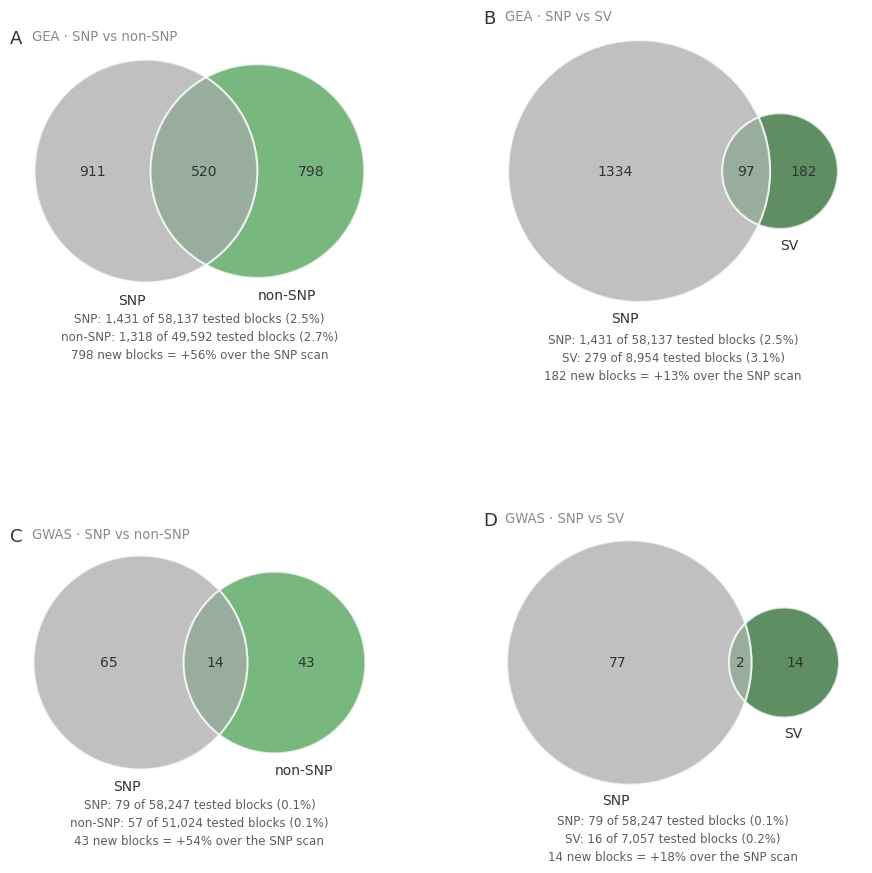

In [2]:
OVERLAP = "#6E8B74"                     # one fixed colour for every overlap lobe

def venn_pair(ax, a, b, la, lb, ca, cb):
    v = venn2([a, b], set_labels=(la, lb), ax=ax)
    for pid, c in [("10", ca), ("01", cb), ("11", OVERLAP)]:
        p = v.get_patch_by_id(pid)
        if p is None: continue
        p.set_color(c); p.set_alpha(0.7); p.set_edgecolor("white"); p.set_linewidth(1.5)
    for t in v.set_labels:
        if t: t.set_color(TH.LABEL); t.set_fontsize(10)
    for t in v.subset_labels:
        if t: t.set_fontsize(10)
    return v

fig, axes = plt.subplots(2, 2, figsize=(11, 10.5), gridspec_kw=dict(hspace=0.55, wspace=0.25))
for r, scan in enumerate(["GEA", "GWAS"]):
    S = blocks(scan, "snp")
    for c, cls in enumerate(["nonsnp", "sv"]):
        ax = axes[r, c]; X = blocks(scan, cls)
        venn_pair(ax, S, X, "SNP", LAB[cls], COL["snp"], COL[cls])
        TH.panel(ax, "ABCD"[2 * r + c], f"{scan} · SNP vs {LAB[cls]}", y=1.02)
        new = len(X - S)
        under(ax, [tlab("SNP", scan, "snp"), tlab(LAB[cls], scan, cls),
                   f"{new:,} new blocks = +{100*new/len(S):.0f}% over the SNP scan"])
plt.savefig(f"{PLOTS}/class_signal_venn_snp_vs_class.png", dpi=150, bbox_inches="tight")
plt.show()

## 2 · GEA — SNP / small indel / SV

Three primary classes separately (non-SNP = the union of the two green circles, but tested
jointly, so not exactly their union). Small indels carry most of the non-SNP signal.

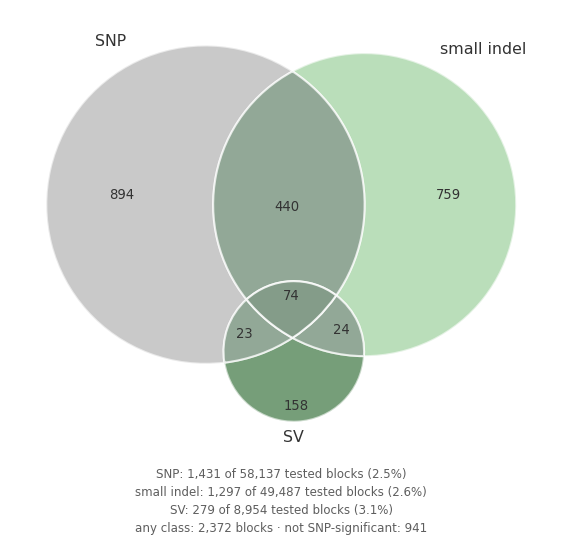

In [3]:
A, B, Cc = blocks("GEA", "snp"), blocks("GEA", "smallindel"), blocks("GEA", "sv")
fig, ax = plt.subplots(figsize=(7, 6.3))
v = venn3([A, B, Cc], set_labels=("SNP", "small indel", "SV"), ax=ax)
for pid, c in [("100", COL["snp"]), ("010", COL["smallindel"]), ("001", COL["sv"])]:
    p = v.get_patch_by_id(pid)
    if p: p.set_color(c); p.set_alpha(0.6)
for pid in ["110", "101", "011", "111"]:
    p = v.get_patch_by_id(pid)
    if p: p.set_color(OVERLAP); p.set_alpha(0.55 + 0.1 * pid.count("1"))
for pid in ["100", "010", "001", "110", "101", "011", "111"]:
    p = v.get_patch_by_id(pid)
    if p: p.set_edgecolor("white"); p.set_linewidth(1.5)
under(ax, [tlab("SNP", "GEA", "snp"), tlab("small indel", "GEA", "smallindel"), tlab("SV", "GEA", "sv"),
           f"any class: {len(A|B|Cc):,} blocks · not SNP-significant: {len((B|Cc)-A):,}"])
plt.savefig(f"{PLOTS}/class_signal_venn3_gea.png", dpi=150, bbox_inches="tight")
plt.show()

## 3 · How new is "new"? Shared / SNP near-miss / SNP-blind

Same blocks as the Venns, with the new lobe split by how close the best SNP in the block came to
the SNP bar. The dark segment is the conservative "SNPs see nothing here" count.

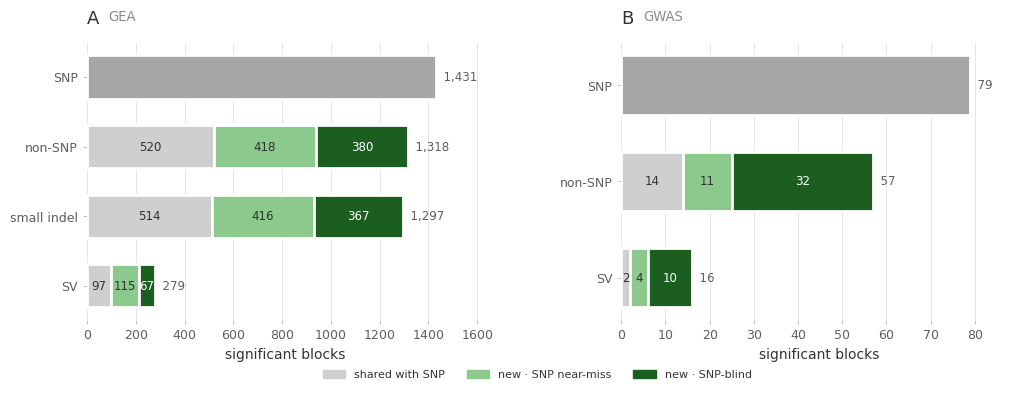

In [4]:
ROWS = [("GEA", "snp"), ("GEA", "nonsnp"), ("GEA", "smallindel"), ("GEA", "sv"),
        ("GWAS", "snp"), ("GWAS", "nonsnp"), ("GWAS", "sv")]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw=dict(width_ratios=[1, 1], wspace=0.35))
for ax, scan in zip(axes, ["GEA", "GWAS"]):
    rows = [c for s, c in ROWS if s == scan][::-1]
    for y, cls in enumerate(rows):
        b = BLK[(BLK.scan == scan) & (BLK.variant_class == cls)]
        if cls == "snp":
            ax.barh(y, len(b), color=COL["snp"], height=0.62, edgecolor="white", linewidth=2)
            ax.text(len(b), y, f"  {len(b):,}", va="center", fontsize=8.5, color=TH.TICK)
            continue
        left = 0
        for st in STATUS:
            n = int((b.status == st).sum())
            ax.barh(y, n, left=left, color=SCOL[st], height=0.62, edgecolor="white", linewidth=2)
            if n >= 0.06 * len(b):
                ax.text(left + n / 2, y, f"{n:,}", va="center", ha="center", fontsize=8.5,
                        color="white" if st == "new_snp_blind" else TH.LABEL)
            left += n
        ax.text(left, y, f"  {len(b):,}", va="center", fontsize=8.5, color=TH.TICK)
    ax.set_yticks(range(len(rows))); ax.set_yticklabels([LAB[c] for c in rows])
    ax.set_xlabel("significant blocks"); TH.grid_only(ax, "x")
    ax.set_xlim(0, ax.get_xlim()[1] * 1.08)
    TH.panel(ax, "A" if scan == "GEA" else "B", scan, y=1.12)
fig.legend(handles=[Patch(color=SCOL[s], label=SLAB[s]) for s in STATUS],
           loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3)
plt.savefig(f"{PLOTS}/class_signal_status_bars.png", dpi=150, bbox_inches="tight")
plt.show()

## 4 · Across climate axes (GEA)

Per axis, significant blocks per class. Here "shared" is judged **within the axis**: a non-SNP/SV
block is shared if the SNP lead of the same block clears the SNP bar *for that axis*; near-miss /
SNP-blind likewise use the same-axis SNP lead. Rows grouped temperature (bio1–11), precipitation
(bio12–19), climate PCs.

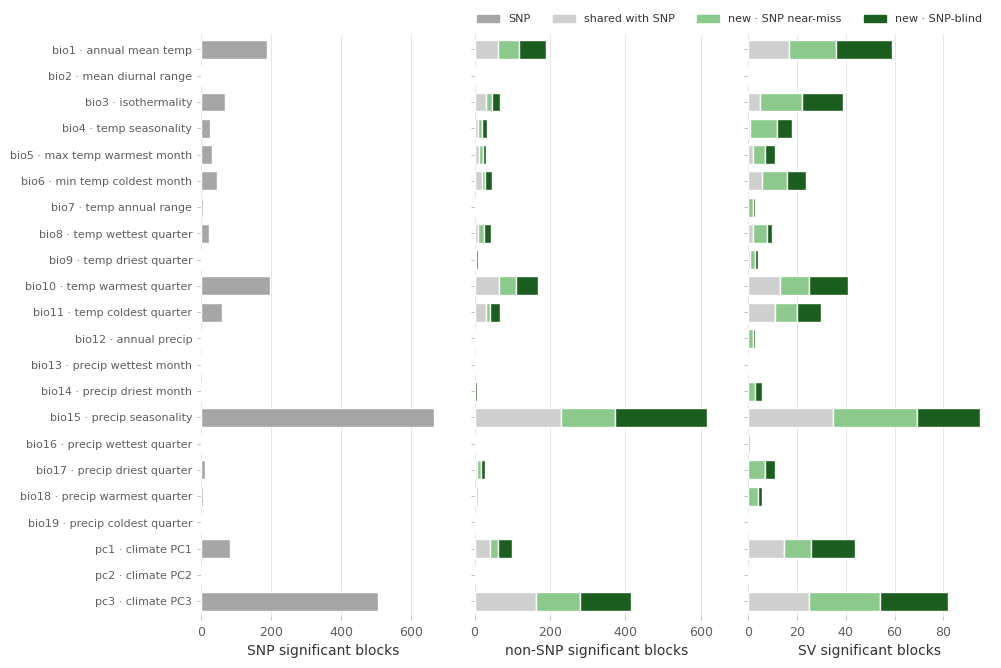

In [5]:
def unit_status(df):
    m = df.snp_margin_same_unit
    return np.where(m > 0, "shared_with_snp", np.where(m > -2, "new_snp_near_miss", "new_snp_blind"))

def per_unit_panel(scan, units, labels, classes, fname, row_h=0.28):
    d = CELLS[CELLS.scan == scan].copy()
    d["st"] = unit_status(d)
    fig, axes = plt.subplots(1, len(classes), figsize=(3.4 * len(classes), row_h * len(units) + 1.4),
                             sharey=True, gridspec_kw=dict(wspace=0.12))
    ys = np.arange(len(units))[::-1]
    for ax, cls in zip(axes, classes):
        dc = d[d.variant_class == cls]
        if cls == "snp":
            n = dc.groupby("unit").size().reindex(units, fill_value=0).to_numpy()
            ax.barh(ys, n, color=COL["snp"], height=0.72, edgecolor="white", linewidth=1)
        else:
            tab = dc.groupby(["unit", "st"]).size().unstack(fill_value=0).reindex(
                index=units, columns=STATUS, fill_value=0)
            left = np.zeros(len(units))
            for st in STATUS:
                ax.barh(ys, tab[st].to_numpy(), left=left, color=SCOL[st], height=0.72,
                        edgecolor="white", linewidth=1)
                left += tab[st].to_numpy()
        ax.set_xlabel(f"{LAB[cls]} significant blocks"); TH.grid_only(ax, "x")
        ax.margins(y=0.01)
    axes[0].set_yticks(ys); axes[0].set_yticklabels(labels, fontsize=8)
    axes[-1].legend(handles=[Patch(color=COL["snp"], label="SNP")] +
                    [Patch(color=SCOL[s], label=SLAB[s]) for s in STATUS],
                    loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=4)
    plt.savefig(f"{PLOTS}/{fname}", dpi=150, bbox_inches="tight")
    plt.show()
    return d

d_gea = per_unit_panel("GEA", AXES, [f"{a} · {BIONAME[a]}" for a in AXES],
                       ["snp", "nonsnp", "sv"], "class_signal_per_axis_gea.png")

In [6]:
# per-axis table: new (not SNP-significant in the same axis) as % of that class' hits
g = d_gea[d_gea.variant_class != "snp"].groupby(["unit", "variant_class"]).st.agg(
    n="size", new=lambda s: (s != "shared_with_snp").sum(), blind=lambda s: (s == "new_snp_blind").sum())
g["% new"] = (100 * g.new / g.n).round(0)
snp_n = d_gea[d_gea.variant_class == "snp"].groupby("unit").size().rename("snp")
t = g.unstack("variant_class").reindex(AXES)
t.columns = [f"{c}_{a}" for a, c in t.columns]
t = t.join(snp_n).fillna(0)
t[["snp", "nonsnp_n", "nonsnp_new", "nonsnp_blind", "nonsnp_% new", "sv_n", "sv_new", "sv_blind", "sv_% new"]].astype(int)

,snp,nonsnp_n,nonsnp_new,nonsnp_blind,nonsnp_% new,sv_n,sv_new,sv_blind,sv_% new
unit,,,,,,,,,
bio1,188,190,127,72,67,59,42,23,71
bio2,1,2,2,2,100,0,0,0,0
bio3,69,68,38,22,56,39,34,17,87
bio4,24,32,23,11,72,18,17,6,94
bio5,31,31,18,9,58,11,9,4,82
bio6,44,47,27,18,57,24,18,8,75
bio7,5,3,2,2,67,3,3,1,100
bio8,23,43,35,19,81,10,8,2,80
bio9,3,8,8,3,100,4,3,1,75


## 5 · Across gardens (GWAS)

Same panels per garden, ordered cold → hot (garden id · bio1 °C). Same-garden rule for "shared".
Most gardens have no hits in any class; the signal is concentrated in a few.

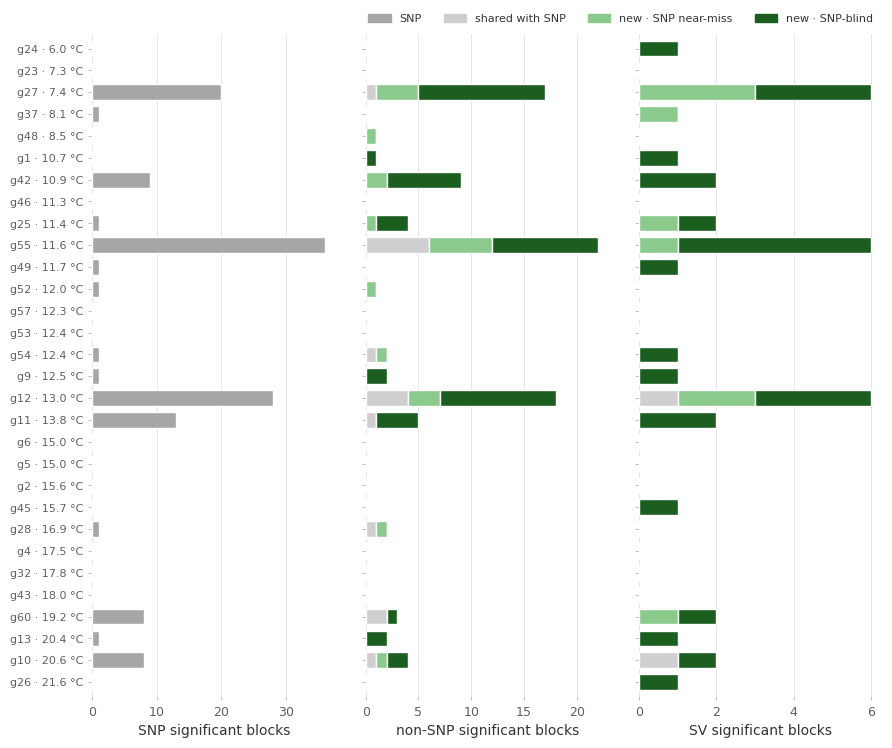

In [7]:
d_gwas = per_unit_panel("GWAS", GARDENS, [f"g{g} · {GARDEN_BIO1[g]:.1f} °C" for g in GARDENS],
                        ["snp", "nonsnp", "sv"], "class_signal_per_garden_gwas.png", row_h=0.24)

## 6 · GEA vs GWAS — do the two scans find the same blocks?

Per class, significant blocks in the GEA (any axis) vs the per-garden GWAS (any garden). Last
panel: only the *new* (not SNP-significant) non-SNP blocks of each scan. The two scans ask
different questions (climate of origin across ecotypes vs selection within one garden), so
exact block agreement is not expected; near-zero overlap is the observation, not a failure
test. Circle areas are proportional to counts.

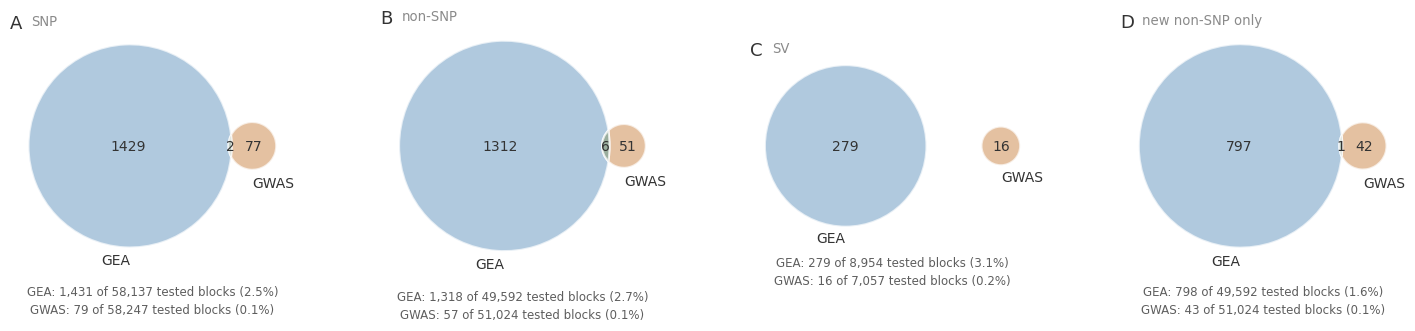

new non-SNP blocks found by BOTH scans: 1
scan         GEA         GWAS
block                        
Chr3_3955  bio15  10;12;27;42


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6), gridspec_kw=dict(wspace=0.3))
for ax, cls, L in zip(axes[:3], ["snp", "nonsnp", "sv"], "ABC"):
    venn_pair(ax, blocks("GEA", cls), blocks("GWAS", cls), "GEA", "GWAS", "#8FB3D1", "#D9A77A")
    under(ax, [tlab("GEA", "GEA", cls), tlab("GWAS", "GWAS", cls)], y=-0.08)
    TH.panel(ax, L, LAB[cls], y=1.05)
newg = set(BLK[(BLK.scan == "GEA") & (BLK.variant_class == "nonsnp") & (BLK.status != "shared_with_snp")].block)
neww = set(BLK[(BLK.scan == "GWAS") & (BLK.variant_class == "nonsnp") & (BLK.status != "shared_with_snp")].block)
venn_pair(axes[3], newg, neww, "GEA", "GWAS", "#8FB3D1", "#D9A77A")
under(axes[3], [tlab("GEA", "GEA", "nonsnp", len(newg)), tlab("GWAS", "GWAS", "nonsnp", len(neww))], y=-0.08)
TH.panel(axes[3], "D", "new non-SNP only", y=1.05)
plt.savefig(f"{PLOTS}/class_signal_gea_vs_gwas.png", dpi=150, bbox_inches="tight")
plt.show()
both = sorted(newg & neww)
print(f"new non-SNP blocks found by BOTH scans: {len(both)}")
if both:
    x = BLK[BLK.block.isin(both) & (BLK.variant_class == "nonsnp")].pivot(
        index="block", columns="scan", values="units")
    print(x.to_string())

## 7 · Recurrence — are the new blocks single-axis / single-garden events?

Number of axes (GEA) or gardens (GWAS) in which the block is significant for its class. GEA
axes are strongly correlated (the temperature bios move together), so multi-axis recurrence is
expected for real climate signal and is not independent replication.

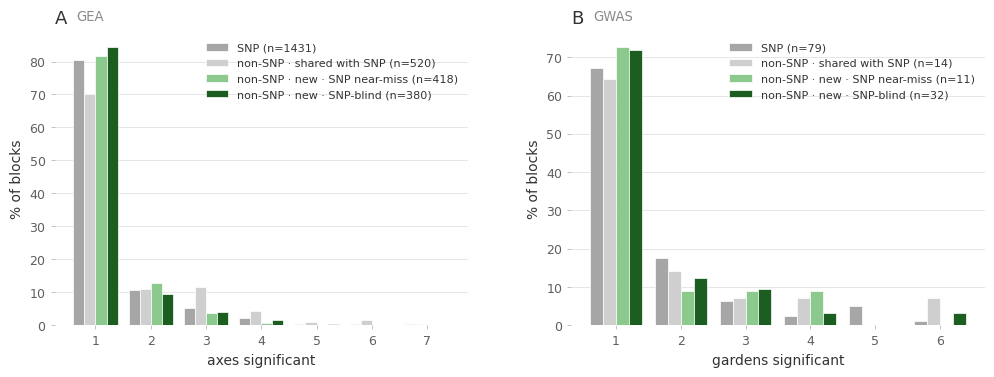

scan  variant_class  status           
GEA   nonsnp         new_snp_blind        84.0
                     new_snp_near_miss    82.0
                     shared_with_snp      70.0
      smallindel     new_snp_blind        84.0
                     new_snp_near_miss    83.0
                     shared_with_snp      71.0
      sv             new_snp_blind        72.0
                     new_snp_near_miss    77.0
                     shared_with_snp      54.0
GWAS  nonsnp         new_snp_blind        72.0
                     new_snp_near_miss    73.0
                     shared_with_snp      64.0
      sv             new_snp_blind        60.0
                     new_snp_near_miss    75.0
                     shared_with_snp       0.0


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(wspace=0.25))
for ax, scan, L in zip(axes, ["GEA", "GWAS"], "AB"):
    b = BLK[(BLK.scan == scan) & BLK.variant_class.isin(["snp", "nonsnp"])].copy()
    b["grp"] = np.where(b.variant_class == "snp", "snp", b.status)
    order = ["snp"] + STATUS
    kmax = int(b.n_units_sig.max()); bins = np.arange(1, kmax + 2)
    w = 0.8 / len(order)
    for i, g in enumerate(order):
        x = b.loc[b.grp == g, "n_units_sig"]
        h, _ = np.histogram(x, bins=bins)
        c = COL["snp"] if g == "snp" else SCOL[g]
        lab = "SNP" if g == "snp" else "non-SNP · " + SLAB[g]
        ax.bar(bins[:-1] + (i - 1.5) * w, 100 * h / max(h.sum(), 1), width=w, color=c,
               label=f"{lab} (n={len(x)})", edgecolor="white", linewidth=0.5)
    ax.set_xlabel("axes significant" if scan == "GEA" else "gardens significant")
    ax.set_ylabel("% of blocks"); TH.grid_only(ax, "y")
    ax.set_xticks(bins[:-1] if kmax <= 22 else bins[:-1:2])
    TH.panel(ax, L, scan, y=1.08)
    ax.legend(loc="upper right")
plt.savefig(f"{PLOTS}/class_signal_recurrence.png", dpi=150, bbox_inches="tight")
plt.show()
print(BLK[BLK.variant_class != "snp"].assign(single=lambda d: d.n_units_sig == 1)
      .groupby(["scan", "variant_class", "status"]).single.mean().mul(100).round(0)
      .rename("% single axis/garden").to_string())

## 8 · The near-miss continuum

Each dot is a significant non-SNP / SV block. x = how far the best SNP in the block sits from the
SNP bar (log10 units, best over axes/gardens; >0 means SNP-significant too); y = how far the class
lead clears its own bar. The dashed line at x = −2 separates near-miss from SNP-blind. A cloud
hugging x ≈ 0 means the new signal is mostly SNP signal that just misses a stricter bar.

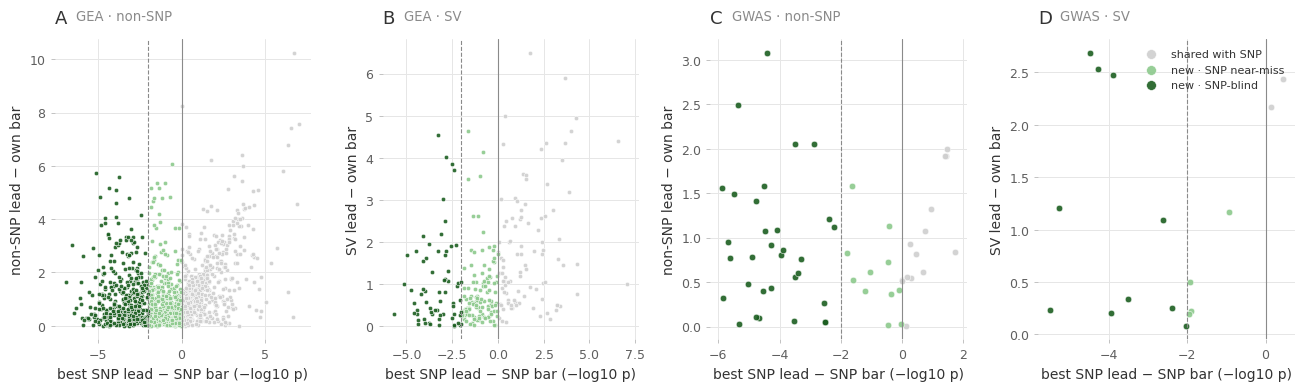

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9), sharey=False, gridspec_kw=dict(wspace=0.28))
for ax, (scan, cls), L in zip(axes, [("GEA", "nonsnp"), ("GEA", "sv"), ("GWAS", "nonsnp"), ("GWAS", "sv")], "ABCD"):
    b = BLK[(BLK.scan == scan) & (BLK.variant_class == cls)]
    x = b.snp_best_margin.fillna(b.snp_best_margin.min() - 1)
    for st in STATUS:
        m = b.status == st
        ax.scatter(x[m], b.best_margin[m], s=10 if scan == "GEA" else 22, color=SCOL[st],
                   edgecolor="white", linewidth=0.4, label=SLAB[st], alpha=0.9)
    for xv in (0, -2):
        ax.axvline(xv, color=TH.MUTED, lw=0.8, ls="--" if xv else "-")
    ax.set_xlabel("best SNP lead − SNP bar (−log10 p)")
    ax.set_ylabel(f"{LAB[cls]} lead − own bar")
    TH.panel(ax, L, f"{scan} · {LAB[cls]}", y=1.1)
axes[-1].legend(loc="upper right", markerscale=1.5)
plt.savefig(f"{PLOTS}/class_signal_near_miss.png", dpi=150, bbox_inches="tight")
plt.show()

## 9 · If the p-values were GIF corrected

Everything above is **raw** p, which is the project decision: λ is recorded per axis and
never divided out. This section is the arithmetic behind that decision — what the same GEA
scan returns if the test statistics are deflated by λ.

**The correction.** χ² ÷ λ, per (class × axis), applied **only where λ > 1**
(`multiaxis/raw_block_significance.py:78-85`). Dividing by a λ < 1 would *manufacture*
signal, so the two deflated axes (pc2 λ 0.74, bio19 0.97) keep their raw p and are unchanged
here. λ itself is genome-wide inflation, median ≈ 1.7 across axes, 3.16 on pc3 and 2.68 on
bio15 — and near-identical across the four variant classes on every axis, so it does not bias
a class contrast, only absolute counts.

**Source.** The GEA production table `r2_gea_nonsnp/phase1_replication/results/multiaxis/
raw_block_significance_lfmm{,_union}.csv` — same 22 axes, same clq0.9 tiling, same rule (the
class's lead record clears that class's bar), unioned over axes. Its raw Bonferroni block
counts agree with this notebook's to within ~1% (snp 1,430 vs 1,431; nonsnp 1,312 vs 1,318;
sv 273 vs 279); the *tested* denominators differ more because that table uses the block column
stored in the LFMM files while this notebook re-assigns tiling blocks itself. Read the section
for the raw → GIF contrast, not as a second estimate of the raw counts.

In [11]:
GEAR = f"{GS}/r2_gea_nonsnp/phase1_replication/results/multiaxis"
U = pd.read_csv(f"{GEAR}/raw_block_significance_lfmm_union.csv")
PA = pd.read_csv(f"{GEAR}/raw_block_significance_lfmm.csv").query("model == 'lfmm'")
REG = [("raw_bonf_blk", "raw · Bonferroni"), ("raw_bh_blk", "raw · BH q<0.05"),
       ("gif_bonf_blk", "GIF · Bonferroni"), ("gif_bh_blk", "GIF · BH q<0.05")]
show = U.set_index("cls").loc[["snp", "nonsnp", "smallindel", "sv"]]
print("significant BLOCKS, union over the 22 climate axes\n")
print(show[["blocks_tested"] + [c for c, _ in REG]]
      .rename(columns=dict(REG, blocks_tested="tested")).to_string())
print("\nas % of that class's tested blocks")
print((100 * show[[c for c, _ in REG]].div(show.blocks_tested, axis=0))
      .round(2).rename(columns=dict(REG)).to_string())
print("\nthe only (class x axis) cells where anything survives GIF:")
print(PA.loc[(PA.gif_bonf_blk > 0) | (PA.gif_bh_blk > 0),
             ["cls", "axis", "lam", "raw_bonf_blk", "raw_bh_blk",
              "gif_bonf_blk", "gif_bh_blk"]].to_string(index=False))

significant BLOCKS, union over the 22 climate axes

            tested  raw · Bonferroni  raw · BH q<0.05  GIF · Bonferroni  GIF · BH q<0.05
cls                                                                                     
snp          56846              1430            39366                 0                0
nonsnp       41908              1312            27674                 0                3
smallindel   41731              1291            27326                 0                0
sv            4520               273             2868                 4                9

as % of that class's tested blocks
            raw · Bonferroni  raw · BH q<0.05  GIF · Bonferroni  GIF · BH q<0.05
cls                                                                             
snp                     2.52            69.25              0.00             0.00
nonsnp                  3.13            66.04              0.00             0.01
smallindel              3.09            65.48         

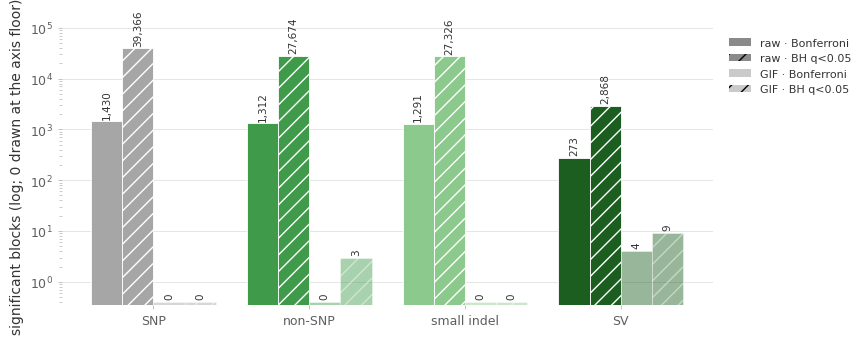

In [12]:
fig, ax = plt.subplots(figsize=(8.4, 3.6))
cls_order = ["snp", "nonsnp", "smallindel", "sv"]
w = 0.8 / len(REG)
hatch = {"raw_bonf_blk": None, "raw_bh_blk": "//", "gif_bonf_blk": None, "gif_bh_blk": "//"}
for i, (col, lab) in enumerate(REG):
    v = [max(int(show.loc[c, col]), 0) for c in cls_order]
    ax.bar(np.arange(len(cls_order)) + (i - 1.5) * w, np.maximum(v, 0.4), width=w,
           color=[COL[c] for c in cls_order], hatch=hatch[col],
           alpha=1.0 if col.startswith("raw") else 0.45,
           edgecolor="white", linewidth=0.6)
    for x, n in zip(np.arange(len(cls_order)) + (i - 1.5) * w, v):
        ax.annotate(f"{n:,}", (x, max(n, 0.4)), ha="center", va="bottom", fontsize=7.5,
                    rotation=90, xytext=(0, 2), textcoords="offset points")
ax.set_yscale("log"); ax.set_ylim(0.35, 1e5)
ax.set_xticks(range(len(cls_order))); ax.set_xticklabels([LAB[c] for c in cls_order])
ax.set_ylabel("significant blocks (log; 0 drawn at the axis floor)")
TH.grid_only(ax, "y")
# outside the axes: the tallest bar and its rotated count label reach the top of the panel
ax.legend(handles=[Patch(facecolor=TH.MUTED, hatch=hatch[c], alpha=1.0 if c.startswith("raw") else 0.45,
                         label=l) for c, l in REG], loc="upper left",
          bbox_to_anchor=(1.01, 1.0), fontsize=8, frameon=False)
plt.savefig(f"{PLOTS}/class_signal_gif.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading it.** The two corrections fail in opposite directions and neither leaves a
usable list. **Raw BH is unusable because it calls almost everything**: 39,366 of 56,846 SNP
blocks (69%) and 27,674 of 41,908 non-SNP blocks (66%) — 90% and 79% of the genome's bases.
That is why the project reports Bonferroni rather than BH on raw p. **GIF is unusable because
it calls almost nothing**: 0 blocks at Bonferroni for snp, nonsnp and smallindel, and the
entire surviving set across all 22 axes and 4 classes is **sv 4 blocks (Bonferroni) / 9 (BH)
and nonsnp 3 (BH)** — from three cells only, sv·bio6, sv·pc1 and nonsnp·bio6, none of them an
inflated axis (λ 1.73–1.89).

So the choice is not between a calibrated list and an uncalibrated one. It is between raw
Bonferroni — 1,430 snp / 1,312 non-SNP / 273 SV blocks, an explicit **candidate net** whose λ
must be quoted beside it — and a statistically airtight empty set. The project takes the
first and ranks candidates on independent lines of evidence instead of on p
(`genes/convergence/README.md`). Two further reasons not to read the GIF column as "the truth":
λ on this data is not pure confounding (the trait *is* climate, and real polygenic climate
adaptation is genuinely correlated with the leading structure of the response, so dividing by
λ removes signal with the artifact), and the correction is one-sided by construction — it can
only ever remove hits, since axes with λ < 1 are left alone.